In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ModuleNotFoundError: No module named 'pandas'

In [5]:
%pip install pandas matplotlib pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\laragon\bin\python\python-3.13\python.exe -m pip install --upgrade pip


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

FileNotFoundError: [WinError 3] Le chemin d’accès spécifié est introuvable: '../beauty360/data/images'

In [4]:
print(os.getcwd())
print(os.listdir("."))
print(os.listdir(".."))

C:\beauty\beauty360\notebooks\venv
['.gitignore', '.ipynb_checkpoints', '01_exploration.ipynb', 'Include', 'Lib', 'pyvenv.cfg', 'Scripts']
['venv']


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [8]:
IMG_DIR = IMG_DIR = r"C:\beauty\beauty360\data\images\Oily-Dry-Skin-Types"

for split in sorted(os.listdir(IMG_DIR)):              # train, valid, test
    split_path = os.path.join(IMG_DIR, split)
    if not os.path.isdir(split_path):
        continue
    print(f"\n=== {split} ===")
    for classe in sorted(os.listdir(split_path)):      # dry, normal, oily
        classe_path = os.path.join(split_path, classe)
        if os.path.isdir(classe_path):
            print(f"{classe:10} : {len(os.listdir(classe_path))} images")


=== test ===
dry        : 35 images
normal     : 59 images
oily       : 40 images

=== train ===
dry        : 652 images
normal     : 1104 images
oily       : 1000 images

=== valid ===
dry        : 71 images
normal     : 111 images
oily       : 80 images


In [3]:
train_dir = os.path.join(IMG_DIR, "train")
classes = sorted(os.listdir(train_dir))

fig, axes = plt.subplots(len(classes), 4, figsize=(10, 3 * len(classes)))
for i, classe in enumerate(classes):
    fichiers = os.listdir(os.path.join(train_dir, classe))[:4]
    for j, f in enumerate(fichiers):
        img = Image.open(os.path.join(train_dir, classe, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{classe}\n{img.size}")
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

FileNotFoundError: [WinError 3] Le chemin d’accès spécifié est introuvable: '../data/images\\train'

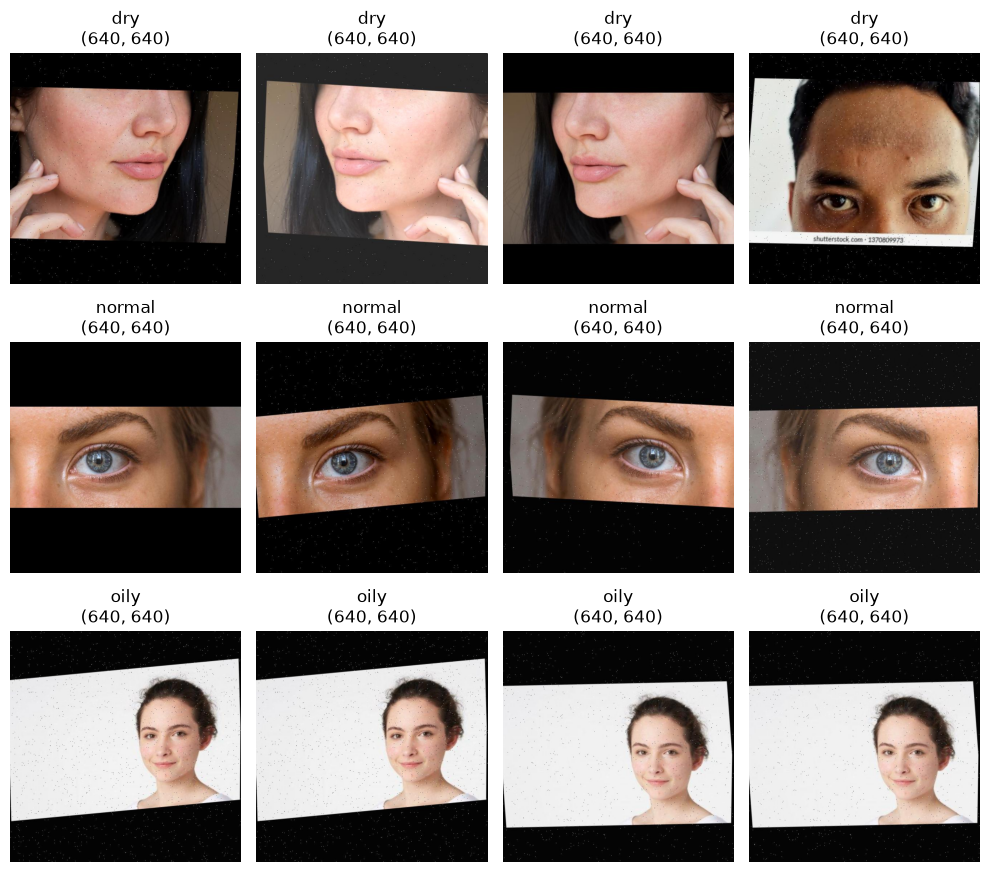

In [4]:
train_dir = os.path.join(IMG_DIR, "train")
classes = sorted(os.listdir(train_dir))

fig, axes = plt.subplots(len(classes), 4, figsize=(10, 3 * len(classes)))
for i, classe in enumerate(classes):
    fichiers = os.listdir(os.path.join(train_dir, classe))[:4]
    for j, f in enumerate(fichiers):
        img = Image.open(os.path.join(train_dir, classe, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{classe}\n{img.size}")
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

In [5]:
df = pd.read_csv("../data/cosmetics.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(1472, 11)
['Label', 'Brand', 'Name', 'Price', 'Rank', 'Ingredients', 'Combination', 'Dry', 'Normal', 'Oily', 'Sensitive']


,Label,Brand,Name,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive
0,Moisturizer,LA MER,Crème de la Mer,175,4.1,"Algae (Seaweed) Extract, Mineral Oil, Petrolat...",1,1,1,1,1
1,Moisturizer,SK-II,Facial Treatment Essence,179,4.1,"Galactomyces Ferment Filtrate (Pitera), Butyle...",1,1,1,1,1
2,Moisturizer,DRUNK ELEPHANT,Protini™ Polypeptide Cream,68,4.4,"Water, Dicaprylyl Carbonate, Glycerin, Ceteary...",1,1,1,1,0
3,Moisturizer,LA MER,The Moisturizing Soft Cream,175,3.8,"Algae (Seaweed) Extract, Cyclopentasiloxane, P...",1,1,1,1,1
4,Moisturizer,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,38,4.1,"Water, Snail Secretion Filtrate, Phenyl Trimet...",1,1,1,1,1


In [6]:
print("Valeurs manquantes :\n", df.isnull().sum())
print("\nDoublons :", df.duplicated().sum())
print("\nCatégories :\n", df["Label"].value_counts())

Valeurs manquantes :
 Label          0
Brand          0
Name           0
Price          0
Rank           0
Ingredients    0
Combination    0
Dry            0
Normal         0
Oily           0
Sensitive      0
dtype: int64

Doublons : 0

Catégories :
 Label
Moisturizer    298
Cleanser       281
Face Mask      266
Treatment      248
Eye cream      209
Sun protect    170
Name: count, dtype: int64


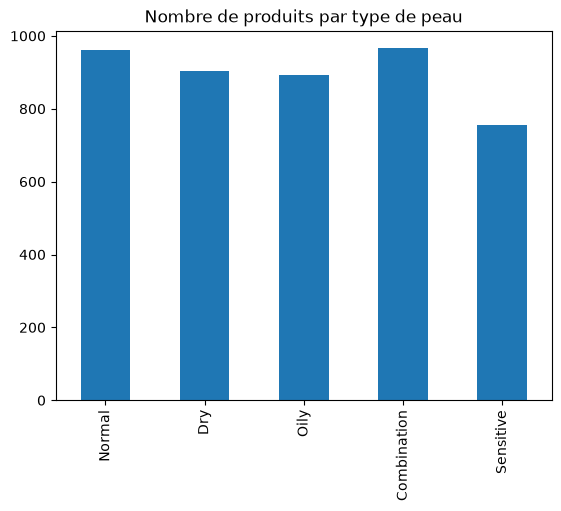

In [7]:
types = ["Normal", "Dry", "Oily", "Combination", "Sensitive"]
df[types].sum().plot(kind="bar", title="Nombre de produits par type de peau")
plt.show()

In [9]:
types = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]

# Problème 1 : ingrédients inexploitables
mauvais_ingr = (df["Ingredients"].str.len() < 30) | \
               (df["Ingredients"].str.contains("No Info", case=False))

# Problème 2 : aucun type de peau
sans_type = df[types].sum(axis=1) == 0

# Problème 3 : doublons marque + nom
doublons = df.duplicated(subset=["Brand", "Name"])

print("Ingrédients inexploitables :", mauvais_ingr.sum())
print("Sans type de peau :", sans_type.sum())
print("Doublons :", doublons.sum())

Ingrédients inexploitables : 126
Sans type de peau : 471
Doublons : 0


In [10]:
a_garder = ~mauvais_ingr & ~sans_type & ~doublons

df_clean = df[a_garder].reset_index(drop=True)

print("Avant :", len(df), "produits")
print("Après :", len(df_clean), "produits")

df_clean.to_csv(r"C:\beauty\beauty360\data\cosmetics_clean.csv", index=False)

Avant : 1472 produits
Après : 939 produits
